# Análisis de latencia del retrieval: base densa vs híbrido vs híbrido + rerank

Lee los tres JSON de latencia ya generados y produce las tablas para el reporte:

| Entrada | Contenido |
|---|---|
| `resultados_retrieval_2_latencia.json` | 9 configuraciones base (3 modelos × 3 chunk sizes, denso puro) |
| `resultados_retrieval_bge_m3_mejorado_latencia.json` | BGE-m3 híbrido + RRF + rerank (cs800) |
| `resultados_retrieval_openai_mejorado_latencia.json` | OpenAI híbrido + RRF (BM25) + rerank (cs800) |

**Salidas** (en `./validacion/reporte_latencias/`):
- `reporte_latencias.xlsx` con las hojas `Resumen`, `Comparacion_cs800`, `Desglose_etapas`, `Por_pregunta`, `Verificaciones` y `Metodologia`.
- Un CSV por tabla, con los mismos datos.
- `boxplot_latencia_total.png` y `desglose_etapas_cs800.png`.

**Decisiones de análisis:**
- **La mediana es la medida principal.** La latencia tiene cola larga, sobre todo por la red hacia OpenRouter, así que la media sola es engañosa. Se reportan también P95 y P99 como medida de la cola.
- **El IC95 de la mediana sale de un bootstrap** (5000 remuestreos, semilla fija para que sea reproducible).
- **Las comparaciones son pareadas por pregunta**, porque las 296 preguntas son las mismas en todas las configuraciones. Para cada pregunta se calcula la diferencia y se reporta la mediana de esas diferencias con su IC95. La prueba de significancia es Wilcoxon de rangos con signo. Con n=296 casi cualquier diferencia sale significativa, así que lo que importa interpretar es el tamaño de la diferencia (ms y razón).
- **El desglose por etapas usa la media.** Las medias sí se suman (media del total = suma de medias por etapa) y las medianas no. Por eso el porcentaje de cada etapa se calcula sobre la media.
- **"Sin embedding" = total − embedding de la consulta.** Aísla el costo local del retrieval. En OpenAI el embedding es mayormente latencia de red hacia la API.

In [2]:
%pip install -q pandas numpy scipy openpyxl matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

DIR_VALIDACION = Path("./validacion")
RUTA_BASE = DIR_VALIDACION / "resultados_retrieval_2_latencia.json"
RUTA_BGE_MEJORADO = DIR_VALIDACION / "resultados_retrieval_bge_m3_mejorado_latencia.json"
RUTA_OPENAI_MEJORADO = DIR_VALIDACION / "resultados_retrieval_openai_mejorado_latencia.json"

DIR_SALIDA = DIR_VALIDACION / "reporte_latencias"
RUTA_EXCEL = DIR_SALIDA / "reporte_latencias.xlsx"

CHUNK_SIZE_COMPARACION = 800
N_BOOTSTRAP = 5000
SEMILLA = 42

NOMBRES_MODELO = {
    "openai/text-embedding-3-large": "OpenAI 3-large",
    "BAAI/bge-m3": "BGE-m3",
    "google/embeddinggemma-300m": "EmbeddingGemma-300m",
}
ORDEN_MODELOS = list(NOMBRES_MODELO.values())

V_BASE, V_SIN_RERANK, V_RERANK = "Denso (base)", "Híbrido sin rerank", "Híbrido + rerank"
ORDEN_VARIANTES = [V_BASE, V_SIN_RERANK, V_RERANK]

NOMBRES_ETAPA = {
    "embedding_consulta": "Embedding de la consulta",
    "busqueda_dispersa": "Búsqueda dispersa",
    "busqueda_densa": "Búsqueda densa",
    "busqueda_densa_y_rrf": "Búsqueda densa + RRF",
    "rerank": "Rerank (cross-encoder)",
}

DIR_SALIDA.mkdir(parents=True, exist_ok=True)

## 1. Carga de los JSON a una tabla por pregunta

In [2]:
def _etiqueta(modelo, cs, variante):
    return f"{modelo} | cs{cs} | {variante}"


def _filas(registros, modelo, cs, variante, archivo):
    filas = []
    for r in registros:
        fila = {"modelo": modelo, "chunk_size": cs, "variante": variante, "archivo": archivo, **r}
        filas.append(fila)
    return filas


filas, meta = [], []

with open(RUTA_BASE, "r", encoding="utf-8") as f:
    base = json.load(f)
for c in base["configuraciones"]:
    modelo = NOMBRES_MODELO.get(c["modelo_embedding"], c["modelo_embedding"])
    filas += _filas(c["latencias_por_pregunta_ms"], modelo, c["chunk_size"], V_BASE, RUTA_BASE.name)
    meta.append({"configuracion": _etiqueta(modelo, c["chunk_size"], V_BASE), "archivo": RUTA_BASE.name,
                 "total_preguntas_archivo": base["total_preguntas"],
                 "contextos_identicos_a_evaluacion": c.get("contextos_identicos_a_evaluacion"),
                 "metodo": base.get("metodo")})

for ruta in (RUTA_BGE_MEJORADO, RUTA_OPENAI_MEJORADO):
    with open(ruta, "r", encoding="utf-8") as f:
        m = json.load(f)
    modelo = NOMBRES_MODELO.get(m["modelo_embedding"], m["modelo_embedding"])
    filas += _filas(m["latencias_por_pregunta_ms"], modelo, m["chunk_size"], V_RERANK, ruta.name)
    meta.append({"configuracion": _etiqueta(modelo, m["chunk_size"], V_RERANK), "archivo": ruta.name,
                 "total_preguntas_archivo": m["total_preguntas"],
                 "contextos_identicos_a_evaluacion": m.get("contextos_identicos_a_evaluacion"),
                 "metodo": m.get("metodo")})

df_preg = pd.DataFrame(filas)
df_preg["configuracion"] = [_etiqueta(m, cs, v) for m, cs, v in zip(df_preg["modelo"], df_preg["chunk_size"], df_preg["variante"])]
df_meta = pd.DataFrame(meta)

# Tabla larga de latencia total: incluye la variante "Híbrido sin rerank" (total - rerank, medida en la misma corrida)
def _total_largo(df, variante, col_total):
    out = df[["modelo", "chunk_size", "id"]].copy()
    out["variante"] = variante
    out["total_ms"] = df[col_total].to_numpy()
    out["sin_embedding_ms"] = out["total_ms"] - df["embedding_consulta"].to_numpy()
    return out


es_base = df_preg["variante"] == V_BASE
df_total = pd.concat([
    _total_largo(df_preg[es_base], V_BASE, "total"),
    _total_largo(df_preg[~es_base], V_SIN_RERANK, "total_sin_rerank"),
    _total_largo(df_preg[~es_base], V_RERANK, "total"),
], ignore_index=True)
df_total["configuracion"] = [_etiqueta(m, cs, v) for m, cs, v in zip(df_total["modelo"], df_total["chunk_size"], df_total["variante"])]

df_total["_om"] = df_total["modelo"].map({m: i for i, m in enumerate(ORDEN_MODELOS)})
df_total["_ov"] = df_total["variante"].map({v: i for i, v in enumerate(ORDEN_VARIANTES)})
df_total = df_total.sort_values(["_om", "chunk_size", "_ov", "id"], kind="stable").drop(columns=["_om", "_ov"]).reset_index(drop=True)
ORDEN_CONFIG = list(dict.fromkeys(df_total["configuracion"]))

print(f"Configuraciones medidas: {df_preg['configuracion'].nunique()} | en el análisis (con 'sin rerank'): {len(ORDEN_CONFIG)}")
print(f"Filas por pregunta: {len(df_preg)}")

Configuraciones medidas: 11 | en el análisis (con 'sin rerank'): 13
Filas por pregunta: 3256


## 2. Verificaciones antes de reportar

Revisa que cada configuración tenga todas las preguntas, que todas usen el mismo conjunto de ids (requisito de la comparación pareada), que no haya tiempos faltantes ni negativos, y cuántos contextos coincidieron con los de la evaluación RAGAS.

In [3]:
ids_referencia = set(df_total.loc[df_total["configuracion"] == ORDEN_CONFIG[0], "id"])
verif = []
for cfg in ORDEN_CONFIG:
    d = df_total[df_total["configuracion"] == cfg]
    fila_meta = df_meta[df_meta["configuracion"] == cfg.replace(V_SIN_RERANK, V_RERANK)].iloc[0]
    verif.append({
        "Configuración": cfg,
        "n preguntas": len(d),
        "n esperado": int(fila_meta["total_preguntas_archivo"]),
        "Mismos ids que las demás": set(d["id"]) == ids_referencia,
        "Ids duplicados": int(d["id"].duplicated().sum()),
        "Tiempos faltantes": int(d["total_ms"].isna().sum()),
        "Tiempos negativos": int((d["total_ms"] < 0).sum()),
        "Contextos idénticos a la evaluación": fila_meta["contextos_identicos_a_evaluacion"],
        "Archivo": fila_meta["archivo"],
    })
df_verif = pd.DataFrame(verif)

problemas = df_verif[
    (df_verif["n preguntas"] != df_verif["n esperado"])
    | (~df_verif["Mismos ids que las demás"])
    | (df_verif["Ids duplicados"] > 0)
    | (df_verif["Tiempos faltantes"] > 0)
    | (df_verif["Tiempos negativos"] > 0)
]
display(df_verif)
if len(problemas):
    print("ATENCIÓN: hay configuraciones con problemas; revisa antes de reportar.")
else:
    print("Verificaciones OK.")

no_identicos = df_verif[df_verif["Contextos idénticos a la evaluación"] < df_verif["n esperado"]]
if len(no_identicos):
    print("Nota: en algunas configuraciones no todos los contextos coinciden con los evaluados (ver columna).")

,Configuración,n preguntas,n esperado,Mismos ids que las demás,Ids duplicados,Tiempos faltantes,Tiempos negativos,Contextos idénticos a la evaluación,Archivo
0,OpenAI 3-large | cs300 | Denso (base),296,296,True,0,0,0,282,resultados_retrieval_2_latencia.json
1,OpenAI 3-large | cs500 | Denso (base),296,296,True,0,0,0,287,resultados_retrieval_2_latencia.json
2,OpenAI 3-large | cs800 | Denso (base),296,296,True,0,0,0,284,resultados_retrieval_2_latencia.json
3,OpenAI 3-large | cs800 | Híbrido sin rerank,296,296,True,0,0,0,295,resultados_retrieval_openai_mejorado_latencia....
4,OpenAI 3-large | cs800 | Híbrido + rerank,296,296,True,0,0,0,295,resultados_retrieval_openai_mejorado_latencia....
5,BGE-m3 | cs300 | Denso (base),296,296,True,0,0,0,296,resultados_retrieval_2_latencia.json
6,BGE-m3 | cs500 | Denso (base),296,296,True,0,0,0,296,resultados_retrieval_2_latencia.json
7,BGE-m3 | cs800 | Denso (base),296,296,True,0,0,0,296,resultados_retrieval_2_latencia.json
8,BGE-m3 | cs800 | Híbrido sin rerank,296,296,True,0,0,0,296,resultados_retrieval_bge_m3_mejorado_latencia....
9,BGE-m3 | cs800 | Híbrido + rerank,296,296,True,0,0,0,296,resultados_retrieval_bge_m3_mejorado_latencia....


Verificaciones OK.
Nota: en algunas configuraciones no todos los contextos coinciden con los evaluados (ver columna).


## 3. Resumen descriptivo por configuración

In [4]:
_rng = np.random.default_rng(SEMILLA)


def ic95_mediana(x, n_boot=N_BOOTSTRAP):
    x = np.asarray(x, dtype=float)
    medianas = np.median(_rng.choice(x, size=(n_boot, x.size), replace=True), axis=1)
    return np.percentile(medianas, [2.5, 97.5])


resumen = []
for cfg in ORDEN_CONFIG:
    d = df_total[df_total["configuracion"] == cfg]
    x = d["total_ms"].to_numpy()
    lo, hi = ic95_mediana(x)
    resumen.append({
        "Configuración": cfg,
        "Modelo": d["modelo"].iloc[0],
        "Chunk size": int(d["chunk_size"].iloc[0]),
        "Variante": d["variante"].iloc[0],
        "n": len(x),
        "Mediana (ms)": np.median(x),
        "IC95 mediana inf (ms)": lo,
        "IC95 mediana sup (ms)": hi,
        "Media (ms)": x.mean(),
        "Desv. est. (ms)": x.std(ddof=1),
        "P90 (ms)": np.percentile(x, 90),
        "P95 (ms)": np.percentile(x, 95),
        "P99 (ms)": np.percentile(x, 99),
        "Mín (ms)": x.min(),
        "Máx (ms)": x.max(),
        "Mediana sin embedding (ms)": np.median(d["sin_embedding_ms"]),
        "Consultas por segundo (1/mediana)": 1000.0 / np.median(x),
    })
df_resumen = pd.DataFrame(resumen)
display(df_resumen.round(1))

,Configuración,Modelo,Chunk size,Variante,n,Mediana (ms),IC95 mediana inf (ms),IC95 mediana sup (ms),Media (ms),Desv. est. (ms),P90 (ms),P95 (ms),P99 (ms),Mín (ms),Máx (ms),Mediana sin embedding (ms),Consultas por segundo (1/mediana)
0,OpenAI 3-large | cs300 | Denso (base),OpenAI 3-large,300,Denso (base),296,642.3,633.2,654.1,677.1,135.4,809.3,854.2,967.6,511.9,2179.1,29.7,1.6
1,OpenAI 3-large | cs500 | Denso (base),OpenAI 3-large,500,Denso (base),296,633.5,625.4,645.8,668.6,135.3,801.1,843.8,955.5,508.1,2169.6,20.6,1.6
2,OpenAI 3-large | cs800 | Denso (base),OpenAI 3-large,800,Denso (base),296,629.4,620.4,640.7,664.3,135.2,797.2,839.5,951.4,505.6,2164.4,15.8,1.6
3,OpenAI 3-large | cs800 | Híbrido sin rerank,OpenAI 3-large,800,Híbrido sin rerank,296,1010.1,931.5,1062.0,1009.6,282.3,1380.5,1449.9,1595.1,564.6,2351.3,9.7,1.0
4,OpenAI 3-large | cs800 | Híbrido + rerank,OpenAI 3-large,800,Híbrido + rerank,296,48124.0,47949.5,48212.9,47977.8,1206.0,49283.3,49717.3,50360.2,41027.7,51640.4,47090.4,0.0
5,BGE-m3 | cs300 | Denso (base),BGE-m3,300,Denso (base),296,268.5,251.6,278.2,261.0,70.4,339.3,348.4,394.4,134.2,699.1,6.1,3.7
6,BGE-m3 | cs500 | Denso (base),BGE-m3,500,Denso (base),296,267.2,248.8,275.1,258.7,69.7,336.1,344.1,390.9,133.2,697.7,3.8,3.7
7,BGE-m3 | cs800 | Denso (base),BGE-m3,800,Denso (base),296,266.4,248.2,275.1,258.5,69.8,335.6,345.7,392.1,132.3,696.7,3.6,3.8
8,BGE-m3 | cs800 | Híbrido sin rerank,BGE-m3,800,Híbrido sin rerank,296,291.8,288.2,294.2,294.0,22.3,322.2,335.8,358.3,246.1,379.1,5.2,3.4
9,BGE-m3 | cs800 | Híbrido + rerank,BGE-m3,800,Híbrido + rerank,296,47049.8,46888.3,47145.5,46378.6,2076.7,48149.6,48316.1,48966.0,36834.4,51118.8,46758.3,0.0


## 4. Comparación pareada en cs800: base → híbrido → híbrido + rerank

Para cada modelo que tiene pipeline mejorado se comparan los pares base → sin rerank, base → con rerank y sin rerank → con rerank. **Δ** es B − A: un valor positivo significa que B es más lento.

In [7]:
def comparar(modelo, var_a, var_b, cs=CHUNK_SIZE_COMPARACION):
    d = df_total[(df_total["modelo"] == modelo) & (df_total["chunk_size"] == cs)]
    piv = d.pivot(index="id", columns="variante", values="total_ms")
    piv_se = d.pivot(index="id", columns="variante", values="sin_embedding_ms")
    if var_a not in piv or var_b not in piv:
        return None
    a, b = piv[var_a].to_numpy(), piv[var_b].to_numpy()
    dif = b - a
    lo, hi = ic95_mediana(dif)
    p = wilcoxon(b, a).pvalue if np.any(dif != 0) else 1.0
    return {
        "Modelo": modelo,
        "Comparación (A → B)": f"{var_a} → {var_b}",
        "n pares": len(dif),
        "Mediana A (ms)": np.median(a),
        "Mediana B (ms)": np.median(b),
        "Δ mediana pareada B−A (ms)": np.median(dif),
        "IC95 Δ inf (ms)": lo,
        "IC95 Δ sup (ms)": hi,
        "Razón de medianas B/A": np.median(b) / np.median(a),
        "% de preguntas donde B es más lento": 100.0 * np.mean(dif > 0),
        "Δ mediana pareada sin embedding (ms)": np.median(piv_se[var_b].to_numpy() - piv_se[var_a].to_numpy()),
        "p (Wilcoxon pareado)": p,
    }


modelos_mejorados = df_total.loc[df_total["variante"] == V_RERANK, "modelo"].unique()
pares = [(V_BASE, V_SIN_RERANK), (V_BASE, V_RERANK), (V_SIN_RERANK, V_RERANK)]
df_comp = pd.DataFrame([r for m in ORDEN_MODELOS if m in modelos_mejorados for a, b in pares if (r := comparar(m, a, b))])
display(df_comp.round(3))

,Modelo,Comparación (A → B),n pares,Mediana A (ms),Mediana B (ms),Δ mediana pareada B−A (ms),IC95 Δ inf (ms),IC95 Δ sup (ms),Razón de medianas B/A,% de preguntas donde B es más lento,Δ mediana pareada sin embedding (ms),p (Wilcoxon pareado)
0,OpenAI 3-large,Denso (base) → Híbrido sin rerank,296,629.434,1010.106,334.689,256.987,387.326,1.605,87.838,-5.894,0.0
1,OpenAI 3-large,Denso (base) → Híbrido + rerank,296,629.434,48124.014,47433.904,47292.317,47551.052,76.456,100.000,47076.101,0.0
2,OpenAI 3-large,Híbrido sin rerank → Híbrido + rerank,296,1010.106,48124.014,47080.272,46962.006,47174.525,47.643,100.000,47080.272,0.0
3,BGE-m3,Denso (base) → Híbrido sin rerank,296,266.437,291.787,33.430,23.481,42.213,1.095,69.595,1.617,0.0
4,BGE-m3,Denso (base) → Híbrido + rerank,296,266.437,47049.752,46783.156,46643.987,46876.840,176.588,100.000,46754.495,0.0
5,BGE-m3,Híbrido sin rerank → Híbrido + rerank,296,291.787,47049.752,46753.585,46596.262,46867.106,161.247,100.000,46753.585,0.0


## 5. Desglose por etapa (medias, que sí se suman)

In [6]:
desglose = []
for cfg in df_preg["configuracion"].unique():
    d = df_preg[df_preg["configuracion"] == cfg]
    media_total = d["total"].mean()
    for col, nombre in NOMBRES_ETAPA.items():
        if col not in d or d[col].isna().all():
            continue
        x = d[col].to_numpy(dtype=float)
        desglose.append({
            "Configuración": cfg,
            "Modelo": d["modelo"].iloc[0],
            "Chunk size": int(d["chunk_size"].iloc[0]),
            "Variante": d["variante"].iloc[0],
            "Etapa": nombre,
            "Media (ms)": x.mean(),
            "Mediana (ms)": np.median(x),
            "P95 (ms)": np.percentile(x, 95),
            "% de la media total": 100.0 * x.mean() / media_total,
        })
    otros = media_total - sum(d[c].mean() for c in NOMBRES_ETAPA if c in d and not d[c].isna().all())
    if abs(otros) < 0.05:  # en la base total = embedding + busqueda exactamente
        continue
    desglose.append({
        "Configuración": cfg, "Modelo": d["modelo"].iloc[0], "Chunk size": int(d["chunk_size"].iloc[0]),
        "Variante": d["variante"].iloc[0], "Etapa": "Otros (overhead Python)",
        "Media (ms)": otros, "Mediana (ms)": np.nan, "P95 (ms)": np.nan,
        "% de la media total": 100.0 * otros / media_total,
    })
df_desglose = pd.DataFrame(desglose)

_om = {m: i for i, m in enumerate(ORDEN_MODELOS)}
df_desglose = df_desglose.sort_values(["Modelo", "Chunk size"], key=lambda s: s.map(_om) if s.name == "Modelo" else s, kind="stable").reset_index(drop=True)
display(df_desglose[df_desglose["Chunk size"] == CHUNK_SIZE_COMPARACION].round(1))

,Configuración,Modelo,Chunk size,Variante,Etapa,Media (ms),Mediana (ms),P95 (ms),% de la media total
4,OpenAI 3-large | cs800 | Denso (base),OpenAI 3-large,800,Denso (base),Embedding de la consulta,649.6,614.2,822.9,97.8
5,OpenAI 3-large | cs800 | Denso (base),OpenAI 3-large,800,Denso (base),Búsqueda densa,14.7,15.8,18.5,2.2
6,OpenAI 3-large | cs800 | Híbrido + rerank,OpenAI 3-large,800,Híbrido + rerank,Embedding de la consulta,999.7,1000.7,1440.2,2.1
7,OpenAI 3-large | cs800 | Híbrido + rerank,OpenAI 3-large,800,Híbrido + rerank,Búsqueda dispersa,2.2,2.2,2.9,0.0
8,OpenAI 3-large | cs800 | Híbrido + rerank,OpenAI 3-large,800,Híbrido + rerank,Búsqueda densa + RRF,7.6,7.6,8.3,0.0
9,OpenAI 3-large | cs800 | Híbrido + rerank,OpenAI 3-large,800,Híbrido + rerank,Rerank (cross-encoder),46968.3,47080.3,48546.0,97.9
14,BGE-m3 | cs800 | Denso (base),BGE-m3,800,Denso (base),Embedding de la consulta,254.7,263.2,339.9,98.5
15,BGE-m3 | cs800 | Denso (base),BGE-m3,800,Denso (base),Búsqueda densa,3.8,3.6,5.8,1.5
16,BGE-m3 | cs800 | Híbrido + rerank,BGE-m3,800,Híbrido + rerank,Embedding de la consulta,288.7,286.6,329.8,0.6
17,BGE-m3 | cs800 | Híbrido + rerank,BGE-m3,800,Híbrido + rerank,Búsqueda dispersa,2.6,2.5,3.6,0.0


## 6. Gráficos

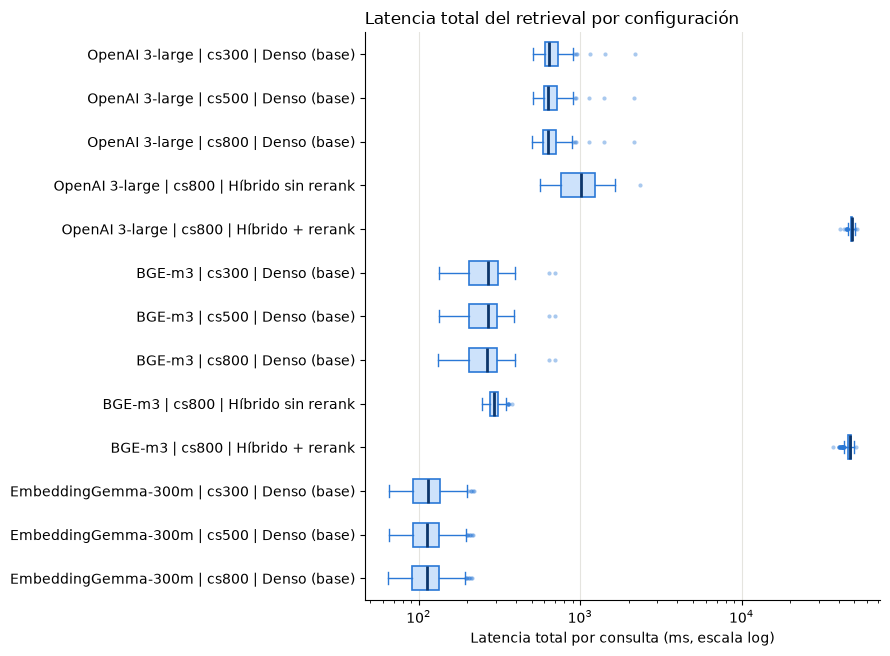

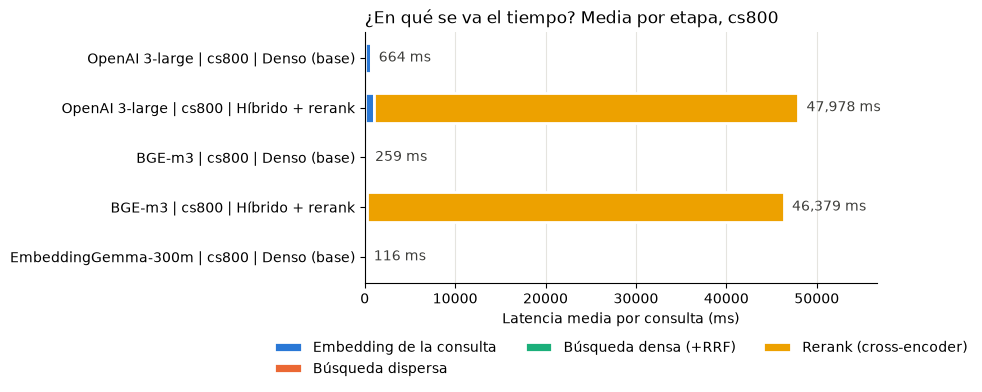

In [8]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
AZUL = "#2a78d6"

# 6.1 Distribución de la latencia total por configuración (escala log: OpenAI y rerank tienen cola larga)
datos = [df_total.loc[df_total["configuracion"] == c, "total_ms"].to_numpy() for c in ORDEN_CONFIG]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(ORDEN_CONFIG) + 1.2))
_horizontal = {"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10) else {"vert": False}
ax.boxplot(datos, **_horizontal, widths=0.55, showfliers=True, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL, linewidth=1.2),
           medianprops=dict(color="#0d366b", linewidth=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=AZUL, markeredgecolor="none", alpha=0.4))
ax.set_yticks(range(1, len(ORDEN_CONFIG) + 1), ORDEN_CONFIG)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("Latencia total por consulta (ms, escala log)")
ax.set_title("Latencia total del retrieval por configuración", loc="left")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(DIR_SALIDA / "boxplot_latencia_total.png", dpi=200)
plt.show()

# 6.2 Desglose de la media por etapa en cs800 (barras apiladas)
COLORES_ETAPA = {
    "Embedding de la consulta": "#2a78d6",
    "Búsqueda dispersa": "#eb6834",
    "Búsqueda densa": "#1baf7a",
    "Búsqueda densa + RRF": "#1baf7a",
    "Rerank (cross-encoder)": "#eda100",
    "Otros (overhead Python)": "#b5b4ad",
}
d800 = df_desglose[df_desglose["Chunk size"] == CHUNK_SIZE_COMPARACION]
cfgs = list(dict.fromkeys(d800["Configuración"]))
fig, ax = plt.subplots(figsize=(9, 0.55 * len(cfgs) + 1.4))
izquierda = np.zeros(len(cfgs))
vistos = set()
for etapa, color in COLORES_ETAPA.items():
    vals = np.array([d800.loc[(d800["Configuración"] == c) & (d800["Etapa"] == etapa), "Media (ms)"].sum() for c in cfgs])
    vals = np.clip(vals, 0, None)
    if not vals.any():
        continue
    etiqueta = "Búsqueda densa (+RRF)" if "densa" in etapa else etapa
    ax.barh(cfgs, vals, left=izquierda, color=color, edgecolor="white", linewidth=2, height=0.6,
            label=None if etiqueta in vistos else etiqueta)
    vistos.add(etiqueta)
    izquierda += vals
for i, total in enumerate(izquierda):
    ax.text(total, i, f"  {total:,.0f} ms", va="center", color="#3d3d3a")
ax.invert_yaxis()
ax.set_xlabel("Latencia media por consulta (ms)")
ax.set_title(f"¿En qué se va el tiempo? Media por etapa, cs{CHUNK_SIZE_COMPARACION}", loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, izquierda.max() * 1.18)
fig.tight_layout()
fig.savefig(DIR_SALIDA / "desglose_etapas_cs800.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Exportar a Excel y CSV

In [11]:
columnas_preg = ["configuracion", "modelo", "chunk_size", "variante", "id", "embedding_consulta", "busqueda_dispersa",
                 "busqueda_densa", "busqueda_densa_y_rrf", "rerank", "total_sin_rerank", "total"]
df_preg_export = df_preg[[c for c in columnas_preg if c in df_preg]].rename(columns={
    "configuracion": "Configuración", "modelo": "Modelo", "chunk_size": "Chunk size", "variante": "Variante", "id": "Id pregunta",
    "embedding_consulta": "Embedding consulta (ms)", "busqueda_dispersa": "Búsqueda dispersa (ms)",
    "busqueda_densa": "Búsqueda densa (ms)", "busqueda_densa_y_rrf": "Búsqueda densa + RRF (ms)",
    "rerank": "Rerank (ms)", "total_sin_rerank": "Total sin rerank (ms)", "total": "Total (ms)",
})

metodos = "; ".join(f"{a}: {m}" for a, m in df_meta.drop_duplicates("archivo")[["archivo", "metodo"]].itertuples(index=False))
df_metodologia = pd.DataFrame({"Tema": [
    "Fuente", "Medición", "Medida principal", "Intervalos", "Comparaciones", "Desglose", "Sin embedding", "Híbrido sin rerank", "Precaución",
], "Detalle": [
    f"{RUTA_BASE.name}, {RUTA_BGE_MEJORADO.name}, {RUTA_OPENAI_MEJORADO.name}",
    metodos,
    "Mediana de la latencia total por consulta; P95/P99 como medida de cola.",
    f"IC95 de la mediana por bootstrap percentil ({N_BOOTSTRAP} remuestreos, semilla {SEMILLA}).",
    "Pareadas por pregunta (mismas preguntas en todas las configuraciones): mediana de las diferencias B−A con IC95 bootstrap y prueba de Wilcoxon de rangos con signo.",
    "Medias por etapa (aditivas); 'Otros' = media total − suma de etapas medidas.",
    "Total − embedding de la consulta: aísla el costo local; en OpenAI el embedding incluye latencia de red a OpenRouter.",
    "Total − rerank, medido en la misma corrida que híbrido + rerank (no es una corrida independiente).",
    "Base y mejorado se midieron en corridas distintas; la comparación supone el mismo equipo y condiciones.",
]})

hojas = {
    "Resumen": df_resumen,
    "Comparacion_cs800": df_comp,
    "Desglose_etapas": df_desglose,
    "Por_pregunta": df_preg_export,
    "Verificaciones": df_verif,
    "Metodologia": df_metodologia,
}

from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

with pd.ExcelWriter(RUTA_EXCEL, engine="openpyxl") as writer:
    for nombre, df in hojas.items():
        df.to_excel(writer, sheet_name=nombre, index=False)
        ws = writer.sheets[nombre]
        ws.freeze_panes = "B2" if nombre != "Metodologia" else "A2"
        for celda in ws[1]:
            celda.font = Font(bold=True, color="FFFFFF")
            celda.fill = PatternFill("solid", fgColor="1C5CAB")
            celda.alignment = Alignment(wrap_text=True, vertical="center")
        ws.row_dimensions[1].height = 32
        for j, col in enumerate(df.columns, start=1):
            letra = get_column_letter(j)
            if nombre == "Metodologia":
                ancho = 18 if j == 1 else 110
            else:
                largo = max([len(str(col)) * 0.7] + [len(str(v)) for v in df[col].head(300)])
                ancho = min(max(10, largo + 2), 48)
            ws.column_dimensions[letra].width = ancho
            if pd.api.types.is_float_dtype(df[col]):
                formato = "0.00E+00" if col.startswith("p (") else ("0.00" if "Razón" in col else "0.0")
                for (c,) in ws.iter_rows(min_row=2, min_col=j, max_col=j):
                    c.number_format = formato
        if nombre == "Metodologia":
            for (c,) in ws.iter_rows(min_row=2, min_col=2, max_col=2):
                c.alignment = Alignment(wrap_text=True, vertical="top")

for nombre, df in hojas.items():
    df.to_csv(DIR_SALIDA / f"{nombre.lower()}.csv", index=False, encoding="utf-8-sig")

print(f"Excel: {RUTA_EXCEL}")
print(f"CSV y PNG en: {DIR_SALIDA}")

Excel: validacion\reporte_latencias\reporte_latencias.xlsx
CSV y PNG en: validacion\reporte_latencias


## 8. Frases base para el reporte

Plantillas generadas a partir de las tablas. Revísalas y ajústalas antes de usarlas en el informe.

In [ ]:
def _r(cfg):
    return df_resumen[df_resumen["Configuración"] == cfg].iloc[0]


for modelo in [m for m in ORDEN_MODELOS if m in modelos_mejorados]:
    cs = CHUNK_SIZE_COMPARACION
    b, s, r = (_r(_etiqueta(modelo, cs, v)) for v in ORDEN_VARIANTES)
    c_br = df_comp[(df_comp["Modelo"] == modelo) & (df_comp["Comparación (A → B)"] == f"{V_BASE} → {V_RERANK}")].iloc[0]
    rer = df_desglose[(df_desglose["Configuración"] == _etiqueta(modelo, cs, V_RERANK)) & (df_desglose["Etapa"] == "Rerank (cross-encoder)")].iloc[0]
    print(
        f"- {modelo} (cs{cs}): la base densa tuvo una mediana de {b['Mediana (ms)']:.0f} ms "
        f"(IC95 {b['IC95 mediana inf (ms)']:.0f}–{b['IC95 mediana sup (ms)']:.0f}; P95 {b['P95 (ms)']:.0f} ms). "
        f"El híbrido sin rerank subió a {s['Mediana (ms)']:.0f} ms, y con rerank a {r['Mediana (ms)']:.0f} ms "
        f"(IC95 {r['IC95 mediana inf (ms)']:.0f}–{r['IC95 mediana sup (ms)']:.0f}; P95 {r['P95 (ms)']:.0f} ms), "
        f"es decir {c_br['Razón de medianas B/A']:.1f}× la base, con {c_br['Δ mediana pareada B−A (ms)']:.0f} ms adicionales por consulta "
        f"(mediana pareada, IC95 {c_br['IC95 Δ inf (ms)']:.0f}–{c_br['IC95 Δ sup (ms)']:.0f}). "
        f"El reranker explica en promedio el {rer['% de la media total']:.0f}% del tiempo del pipeline mejorado."
    )